In [1]:
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str((Path.cwd() / ".mpl-cache").resolve()))

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFpressurePNM
from RMFsolver.phase_velocity import PQM

plt.rcParams.update({
    "figure.figsize": (7.0, 5.0),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 12,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
})


/Users/janshao/NSM_related/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
PARAM = para.paraQMCRMF3
NM_TYPE = "PNM"

# Quark-matter settings
m_s = 0.0
mu_K = 0.0

# Default bag-constant setup
CALIBRATE_B_FROM_NCRIT0 = True
n0 = 0.16 * const.MeV_fm**3
n_crit0 = 3.0 * n0
B_SQM_MANUAL = 180.0  # MeV, interpreted as B^(1/4)

# Phase-diagram scan window
T_values = np.linspace(0.0, 120.0, 41)
mu_scan = np.linspace(850.0, 1600.0, 180)

print(f"Using {NM_TYPE} with para.paraQMCRMF3")
print(f"n0 = {n0:.3e} MeV^3")


Using PNM with para.paraQMCRMF3
n0 = 1.229e+06 MeV^3


In [3]:
def pnm_pressure_muB(mu_B, T, param=PARAM):
    value = RMFpressurePNM(
        input_num=float(mu_B),
        input_type="muB",
        Trmf=float(T),
        para=param,
        sigma_init=30,
        w0_init=20,
        r03_init=-3,
        mub_init=max(990.0, float(mu_B)),
        verb=False,
    )
    if value is None:
        return np.nan
    return float(np.asarray(value).item())


def pnm_pressure_nB(n_B, T, param=PARAM):
    value = RMFpressurePNM(
        input_num=float(n_B),
        input_type="nB",
        Trmf=float(T),
        para=param,
        sigma_init=30,
        w0_init=20,
        r03_init=-3,
        mub_init=990.0,
        verb=False,
    )
    if value is None:
        return np.nan
    return float(np.asarray(value).item())


def qm_pressure_muB(mu_B, T, B_SQM, mu_K=mu_K, m_s=m_s):
    return float(PQM(mu_B, mu_K, B_SQM, T, ms=m_s))


def omega_pnm(mu_B, T, param=PARAM):
    return -pnm_pressure_muB(mu_B, T, param=param)


def omega_qm(mu_B, T, B_SQM, mu_K=mu_K, m_s=m_s):
    return -qm_pressure_muB(mu_B, T, B_SQM, mu_K=mu_K, m_s=m_s)


def delta_omega(mu_B, T, B_SQM, param=PARAM):
    return omega_qm(mu_B, T, B_SQM) - omega_pnm(mu_B, T, param=param)


In [4]:
def _safe_eval(func, x):
    try:
        value = float(func(float(x)))
    except Exception:
        return np.nan
    if not np.isfinite(value):
        return np.nan
    return value


def find_root_on_grid(func, x_grid, prefer=None):
    x_grid = np.asarray(x_grid, dtype=float)
    values = np.array([_safe_eval(func, x) for x in x_grid], dtype=float)

    finite = np.isfinite(values)
    x_grid = x_grid[finite]
    values = values[finite]

    if x_grid.size < 2:
        return np.nan

    zero_hits = np.where(np.isclose(values, 0.0, atol=1e-8, rtol=0.0))[0]
    if zero_hits.size:
        return float(x_grid[zero_hits[0]])

    sign_changes = np.where(values[:-1] * values[1:] < 0.0)[0]
    if sign_changes.size == 0:
        return np.nan

    if prefer is None:
        idx = sign_changes[0]
    else:
        midpoints = 0.5 * (x_grid[sign_changes] + x_grid[sign_changes + 1])
        idx = sign_changes[np.argmin(np.abs(midpoints - prefer))]

    a = float(x_grid[idx])
    b = float(x_grid[idx + 1])
    return float(brentq(func, a, b, xtol=1e-6, rtol=1e-8, maxiter=200))


def solve_bag_constant_from_ncrit0(n_crit0, mu_grid=None, B_grid=None):
    if mu_grid is None:
        mu_grid = np.linspace(900.0, 1500.0, 220)
    if B_grid is None:
        B_grid = np.linspace(120.0, 260.0, 281)

    P_crit0 = pnm_pressure_nB(n_crit0, 0.0)
    muB_crit0 = find_root_on_grid(
        lambda mu: pnm_pressure_muB(mu, 0.0) - P_crit0,
        mu_grid,
        prefer=1050.0,
    )
    B_SQM = find_root_on_grid(
        lambda B: qm_pressure_muB(muB_crit0, 0.0, B) - P_crit0,
        B_grid,
        prefer=180.0,
    )
    return P_crit0, muB_crit0, B_SQM


def phase_boundary_muB(T, B_SQM, mu_grid=mu_scan, prefer=None, param=PARAM):
    return find_root_on_grid(
        lambda mu: delta_omega(mu, T, B_SQM, param=param),
        mu_grid,
        prefer=prefer,
    )


In [5]:
if CALIBRATE_B_FROM_NCRIT0:
    P_crit0, muB_crit0, B_SQM = solve_bag_constant_from_ncrit0(n_crit0)
else:
    P_crit0 = np.nan
    muB_crit0 = np.nan
    B_SQM = float(B_SQM_MANUAL)

muB_crit_values = []
mu_prefer = None

for T in T_values:
    root = phase_boundary_muB(T, B_SQM, mu_grid=mu_scan, prefer=mu_prefer)
    muB_crit_values.append(root)
    if np.isfinite(root):
        mu_prefer = root

muB_crit_values = np.array(muB_crit_values, dtype=float)
valid = np.isfinite(muB_crit_values)

print(f"B^(1/4) = {B_SQM:.3f} MeV")
if np.isfinite(muB_crit0):
    print(f"T=0 calibration: n_crit0/n0 = {n_crit0 / n0:.2f}, muB_crit0 = {muB_crit0:.3f} MeV")
print(f"Phase-boundary points found: {valid.sum()} / {len(T_values)}")

if not np.any(valid):
    raise RuntimeError("No phase boundary found on the chosen grid. Expand mu_scan or revisit the bag calibration.")


B^(1/4) = 189.157 MeV
T=0 calibration: n_crit0/n0 = 3.00, muB_crit0 = 1190.934 MeV
Phase-boundary points found: 26 / 41


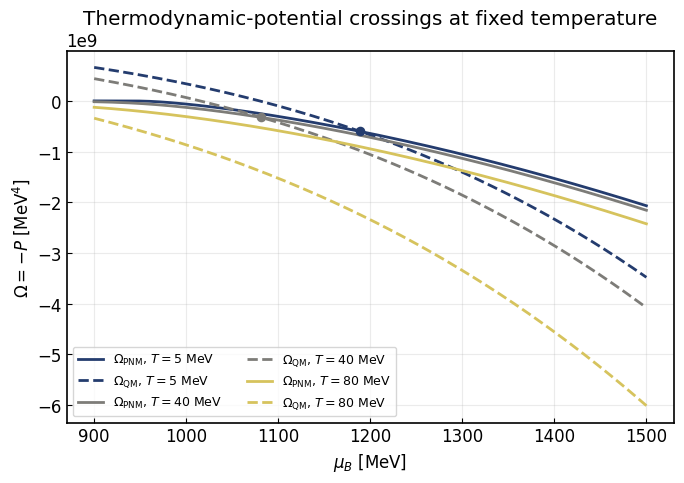

In [8]:
sample_temperatures = [5.0, 40.0, 80.0]
mu_plot = np.linspace(900.0, 1500.0, 160)
colors = plt.cm.cividis(np.linspace(0.15, 0.85, len(sample_temperatures)))

fig, ax = plt.subplots()

for color, T in zip(colors, sample_temperatures):
    omega_n = np.array([omega_pnm(mu, T) for mu in mu_plot])
    omega_q = np.array([omega_qm(mu, T, B_SQM) for mu in mu_plot])
    ax.plot(mu_plot, omega_n, color=color, lw=2.0, label=rf"$\Omega_{{\rm PNM}}$, $T={T:.0f}$ MeV")
    ax.plot(mu_plot, omega_q, color=color, lw=2.0, ls="--", label=rf"$\Omega_{{\rm QM}}$, $T={T:.0f}$ MeV")

    mu_cross = phase_boundary_muB(T, B_SQM, mu_grid=mu_plot)
    if np.isfinite(mu_cross):
        ax.scatter([mu_cross], [omega_pnm(mu_cross, T)], color=color, s=35, zorder=5)

ax.set_xlabel(r"$\mu_B$ [MeV]")
ax.set_ylabel(r"$\Omega = -P$ [MeV$^4$]")
ax.set_title("Thermodynamic-potential crossings at fixed temperature")
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()


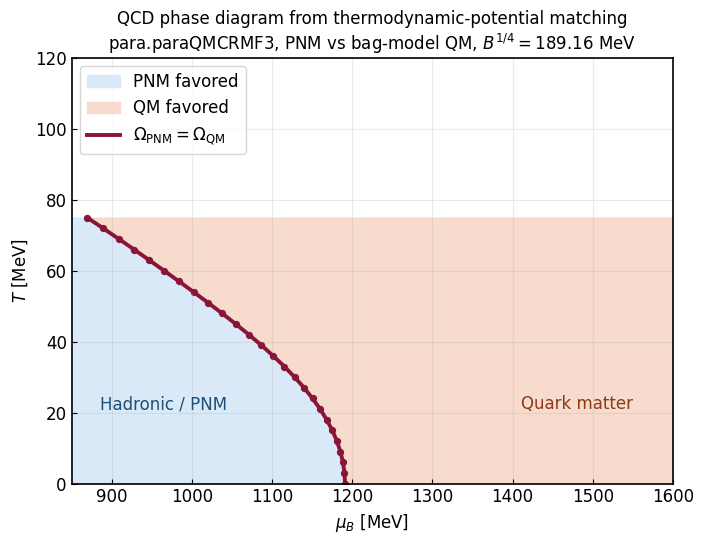

In [10]:
fig, ax = plt.subplots(figsize=(7.2, 5.6))

T_boundary = T_values[valid]
mu_boundary = muB_crit_values[valid]
mu_min = float(mu_scan.min())
mu_max = float(mu_scan.max())

ax.fill_betweenx(T_boundary, mu_min, mu_boundary, color="#d8e8f8", alpha=0.95, label="PNM favored")
ax.fill_betweenx(T_boundary, mu_boundary, mu_max, color="#f7d8c8", alpha=0.90, label="QM favored")
ax.plot(mu_boundary, T_boundary, color="#8a1538", lw=2.8, label=r"$\Omega_{\rm PNM}=\Omega_{\rm QM}$")
ax.scatter(mu_boundary, T_boundary, color="#8a1538", s=18)

ax.text(mu_min + 35.0, T_boundary[min(5, len(T_boundary) - 1)] + 6.0, "Hadronic / PNM", color="#1f4e79")
ax.text(mu_max - 190.0, T_boundary[min(5, len(T_boundary) - 1)] + 6.0, "Quark matter", color="#8b3a1a")

title = "QCD phase diagram from thermodynamic-potential matching"
subtitle = rf"para.paraQMCRMF3, PNM vs bag-model QM, $B^{{1/4}}={B_SQM:.2f}$ MeV"
ax.set_title(title + "\n" + subtitle, fontsize=12)
ax.set_xlabel(r"$\mu_B$ [MeV]")
ax.set_ylabel(r"$T$ [MeV]")
ax.set_xlim(mu_min, mu_max)
ax.set_ylim(T_values.min(), T_values.max())
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
